# Fashion-MNIST Generative Modelling
**Week 19 Graded Mini Project** · Arpit Jain

This notebook builds four generative components on Fashion-MNIST (28×28 greyscale clothing images, 10 classes):

| Task | Model | What it teaches |
|---|---|---|
| 2 | Denoising Autoencoder (DAE) | compression to a 32-dim code and reconstruction from noisy inputs |
| 3 | Variational Autoencoder (VAE) | a probabilistic latent space you can sample, interpolate and traverse |
| 4 | Conditional GAN (cGAN) | adversarial training with class-label control |
| 5 | StyleGAN-lite (AdaIN) | style mixing by swapping feature statistics |

Every figure is also saved to `results/` (Figures 1-7 plus training curves), and the key numbers to `results/metrics.json`.

# Task 1: Setup

## 1.1 Enable GPU
In Colab: **Runtime → Change runtime type → Hardware accelerator: GPU (T4)**, then run all cells. The cell below picks the best available device: `cuda` (NVIDIA GPU, e.g. Colab), then `mps` (Apple-silicon GPU), then `cpu`.

In [1]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: mps


## 1.2 Install and import libraries

In [2]:
# Colab already ships torch / torchvision / matplotlib / tqdm; this installs them only if missing.
import importlib.util, subprocess, sys
missing = [p for p in ["torch", "torchvision", "matplotlib", "tqdm"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import json, math, random, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
METRICS = {"device": str(device)}
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.14.1 | torchvision 0.29.1


## 1.3 Load Fashion-MNIST

In [3]:
tfm = transforms.ToTensor()                                  # pixels in [0, 1]
train_ds = datasets.FashionMNIST("data", train=True, download=True, transform=tfm)
test_ds = datasets.FashionMNIST("data", train=False, download=True, transform=tfm)
BATCH = 128
workers = 2 if device.type == "cuda" else 0
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=workers, drop_last=True)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=workers)
CLASSES = train_ds.classes
x0, y0 = next(iter(train_loader))
print(f"train {len(train_ds)} | test {len(test_ds)} | batch {tuple(x0.shape)} | pixel range [{x0.min():.0f}, {x0.max():.0f}]")
print("classes:", CLASSES)

train 60000 | test 10000 | batch (128, 1, 28, 28) | pixel range [0, 1]
classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 1.4 Visualisation helper

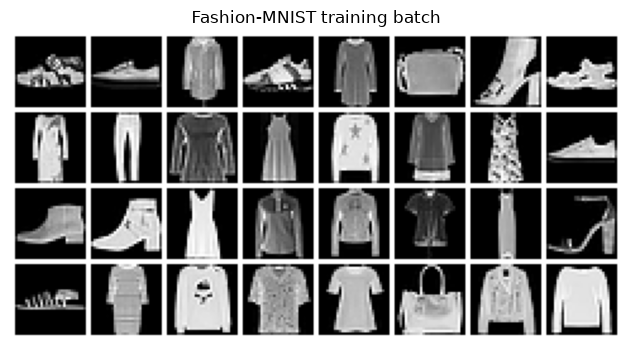

In [4]:
def show_grid(images, nrow=8, title=None, save=None, figsize=None, ax=None):
    """Show a batch of images (N,1,28,28) in [0,1] (or [-1,1], rescaled) as one grid; optionally save it."""
    imgs = images.detach().cpu().float()
    if imgs.min() < 0:                       # GAN outputs are in [-1, 1]
        imgs = (imgs + 1) / 2
    grid = make_grid(imgs.clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=figsize or (nrow * 0.9, math.ceil(len(imgs) / nrow) * 0.9))
    ax.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray"); ax.axis("off")
    if title: ax.set_title(title)
    if own:
        plt.tight_layout()
        if save: plt.savefig(RESULTS / save, dpi=130, bbox_inches="tight")
        plt.show()

show_grid(x0[:32], nrow=8, title="Fashion-MNIST training batch", save="00_dataset_batch.png")

# Task 2: Denoising Autoencoder

## 2.1 Model
- **Encoder:** two stride-2 convolutions (28 → 14 → 7) and a linear layer to a **32-dim latent z**.
- **Decoder:** a linear layer back to 64×7×7, then two transposed convolutions (7 → 14 → 28) and a **Sigmoid**, so outputs are in [0, 1].

In [5]:
LATENT_AE = 32

class Encoder(nn.Module):
    def __init__(self, z_dim, out_mult=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),        # 28 -> 14
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),       # 14 -> 7
            nn.Flatten())
        self.fc = nn.Linear(64 * 7 * 7, z_dim * out_mult)
    def forward(self, x):
        return self.fc(self.conv(x))

class Decoder(nn.Module):
    def __init__(self, z_dim):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z_dim, 64 * 7 * 7), nn.ReLU())
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())  # 14 -> 28
    def forward(self, z):
        return self.deconv(self.fc(z).view(-1, 64, 7, 7))

class DAE(nn.Module):
    def __init__(self, z_dim=LATENT_AE):
        super().__init__()
        self.enc, self.dec = Encoder(z_dim), Decoder(z_dim)
    def forward(self, x):
        return self.dec(self.enc(x))

dae = DAE().to(device)
print(dae); print("parameters:", sum(p.numel() for p in dae.parameters()))

DAE(
  (enc): Encoder(
    (conv): Sequential(
      (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Flatten(start_dim=1, end_dim=-1)
    )
    (fc): Linear(in_features=3136, out_features=32, bias=True)
  )
  (dec): Decoder(
    (fc): Sequential(
      (0): Linear(in_features=32, out_features=3136, bias=True)
      (1): ReLU()
    )
    (deconv): Sequential(
      (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): Sigmoid()
    )
  )
)
parameters: 270561


## 2.2 Add noise
Gaussian noise with σ = 0.3, then clamp to [0, 1] so noisy images stay valid pixels.

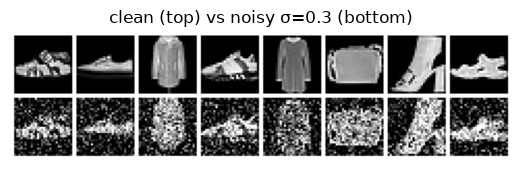

In [6]:
SIGMA = 0.3
def add_noise(x, sigma=SIGMA):
    return (x + sigma * torch.randn_like(x)).clamp(0, 1)

show_grid(torch.cat([x0[:8], add_noise(x0[:8])]), nrow=8, title="clean (top) vs noisy σ=0.3 (bottom)")

## 2.3 Train
MSE between the denoised output and the **clean** image, Adam (lr 1e-3), 10 epochs. Test loss is tracked every epoch.

epoch  1 | train MSE 0.0284 | test MSE 0.0164


epoch  2 | train MSE 0.0148 | test MSE 0.0137


epoch  3 | train MSE 0.0130 | test MSE 0.0127


epoch  4 | train MSE 0.0122 | test MSE 0.0121


epoch  5 | train MSE 0.0117 | test MSE 0.0115


epoch  6 | train MSE 0.0113 | test MSE 0.0113


epoch  7 | train MSE 0.0111 | test MSE 0.0111


epoch  8 | train MSE 0.0108 | test MSE 0.0110


epoch  9 | train MSE 0.0107 | test MSE 0.0107


epoch 10 | train MSE 0.0105 | test MSE 0.0106


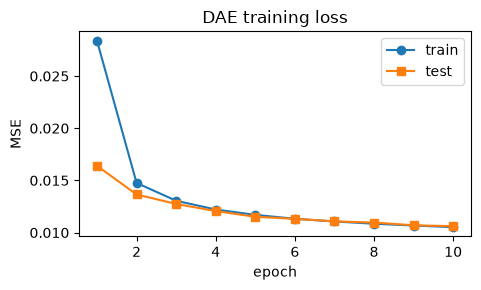

In [7]:
def psnr(a, b):
    mse = F.mse_loss(a, b, reduction="none").flatten(1).mean(1)
    return (10 * torch.log10(1.0 / mse.clamp_min(1e-10))).mean().item()

opt = torch.optim.Adam(dae.parameters(), lr=1e-3)
EPOCHS_DAE = 10
dae_hist = []
t0 = time.time()
for epoch in range(1, EPOCHS_DAE + 1):
    dae.train(); tr = 0
    for x, _ in tqdm(train_loader, desc=f"DAE epoch {epoch}", leave=False):
        x = x.to(device)
        loss = F.mse_loss(dae(add_noise(x)), x)
        opt.zero_grad(); loss.backward(); opt.step(); tr += loss.item()
    dae.eval(); te = 0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device); te += F.mse_loss(dae(add_noise(x)), x, reduction="sum").item()
    dae_hist.append({"epoch": epoch, "train_mse": tr / len(train_loader), "test_mse": te / (len(test_ds) * 784)})
    print(f"epoch {epoch:2d} | train MSE {dae_hist[-1]['train_mse']:.4f} | test MSE {dae_hist[-1]['test_mse']:.4f}")
METRICS["dae_train_minutes"] = round((time.time() - t0) / 60, 2)

plt.figure(figsize=(5, 3))
plt.plot([h["epoch"] for h in dae_hist], [h["train_mse"] for h in dae_hist], "o-", label="train")
plt.plot([h["epoch"] for h in dae_hist], [h["test_mse"] for h in dae_hist], "s-", label="test")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("DAE training loss"); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS / "dae_loss.png", dpi=130); plt.show()

## 2.4 Outputs
### Figure 1: clean vs noisy vs denoised

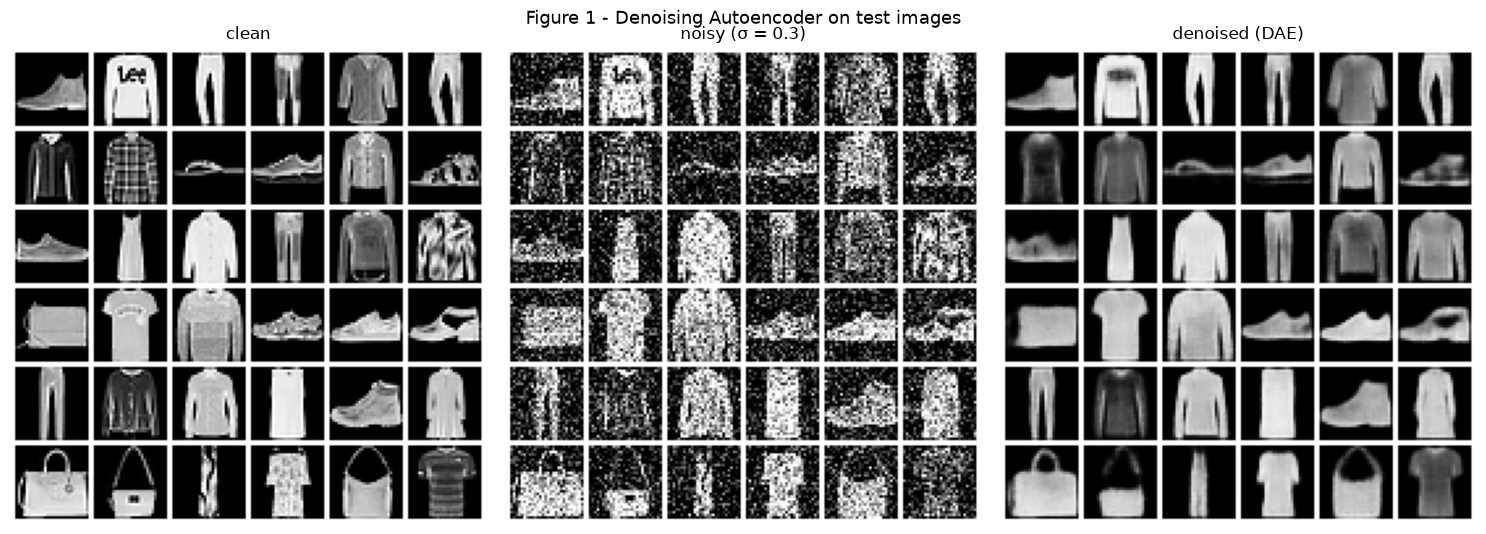

In [8]:
dae.eval()
xt, yt = next(iter(test_loader))
torch.manual_seed(SEED)
xt = xt[:36].to(device); noisy = add_noise(xt)
with torch.no_grad():
    den = dae(noisy)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, imgs, t in zip(axes, [xt, noisy, den], ["clean", "noisy (σ = 0.3)", "denoised (DAE)"]):
    show_grid(imgs, nrow=6, title=t, ax=ax)
plt.suptitle("Figure 1 - Denoising Autoencoder on test images", fontsize=13)
plt.tight_layout(); plt.savefig(RESULTS / "fig1_dae_clean_noisy_denoised.png", dpi=130, bbox_inches="tight"); plt.show()

In [9]:
# Quantify what gets fixed: PSNR of noisy vs denoised, and which classes are hardest
per_class, noisy_psnr, den_psnr = {c: [] for c in range(10)}, [], []
torch.manual_seed(SEED)
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device); n = add_noise(x); d = dae(n)
        noisy_psnr.append(psnr(n, x)); den_psnr.append(psnr(d, x))
        err = F.mse_loss(d, x, reduction="none").flatten(1).mean(1).cpu()
        for c in range(10): per_class[c] += err[y == c].tolist()
cls_mse = {CLASSES[c]: float(np.mean(v)) for c, v in per_class.items()}
METRICS["dae"] = {"test_mse": dae_hist[-1]["test_mse"], "psnr_noisy_db": float(np.mean(noisy_psnr)),
                  "psnr_denoised_db": float(np.mean(den_psnr)),
                  "worst_classes": sorted(cls_mse, key=cls_mse.get, reverse=True)[:3],
                  "best_classes": sorted(cls_mse, key=cls_mse.get)[:3], "per_class_mse": cls_mse}
print(f"PSNR noisy {METRICS['dae']['psnr_noisy_db']:.1f} dB -> denoised {METRICS['dae']['psnr_denoised_db']:.1f} dB")
print("per-class reconstruction MSE (high = hard):")
for k, v in sorted(cls_mse.items(), key=lambda kv: -kv[1]): print(f"  {k:12s} {v:.4f}")

PSNR noisy 12.8 dB -> denoised 20.5 dB
per-class reconstruction MSE (high = hard):
  Bag          0.0157
  Sandal       0.0153
  Shirt        0.0110
  Pullover     0.0102
  T-shirt/top  0.0099
  Dress        0.0098
  Ankle boot   0.0098
  Coat         0.0094
  Sneaker      0.0092
  Trouser      0.0057


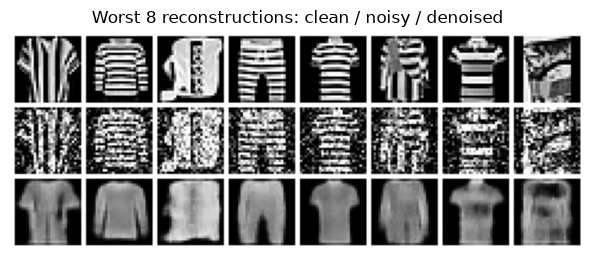

labels of worst cases: ['Shirt', 'Pullover', 'Bag', 'Trouser', 'T-shirt/top', 'Shirt', 'T-shirt/top', 'T-shirt/top']


In [10]:
# failure modes: the test images the DAE reconstructs worst
errs, imgs_all = [], []
torch.manual_seed(SEED)
with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device); n = add_noise(x); d = dae(n)
        errs.append(F.mse_loss(d, x, reduction="none").flatten(1).mean(1).cpu()); imgs_all.append((x.cpu(), n.cpu(), d.cpu()))
errs = torch.cat(errs); worst = errs.argsort(descending=True)[:8]
X = torch.cat([a for a, _, _ in imgs_all]); N = torch.cat([b for _, b, _ in imgs_all]); D = torch.cat([c for _, _, c in imgs_all])
show_grid(torch.cat([X[worst], N[worst], D[worst]]), nrow=8, title="Worst 8 reconstructions: clean / noisy / denoised",
          save="fig1b_dae_failure_cases.png")
print("labels of worst cases:", [CLASSES[test_ds.targets[i]] for i in worst.tolist()])

**Observations (DAE)**

- **What gets fixed:** the Gaussian noise is almost completely removed. PSNR rises from 12.8 dB (noisy) to 20.5 dB (denoised), and the silhouette, the background and the overall brightness of every garment come back cleanly (Figure 1).
- **What is lost:** fine high-frequency detail. The "Lee" logo, plaid checks, stripes and printed patterns are smoothed into flat grey. A 32-number code cannot store texture, so the decoder outputs the average look of the garment's shape.
- **Failure modes:** the 8 worst reconstructions are all strongly striped or patterned tops and trousers. Their stripes disappear completely, and the noise had already hidden them at σ = 0.3.
- **Per class:** Bag (MSE 0.016), Sandal (0.015) and Shirt (0.011) are the hardest. Bags vary a lot in shape, and sandals are thin straps that the noise easily swamps. Trouser (0.006) and Sneaker are the easiest, because their shapes are simple and consistent.
- **Remaining artifacts:** outputs are slightly blurry, with soft edges and a faint halo around bright items. This is typical of an MSE-trained decoder, which averages over the possible clean images.

# Task 3: Variational Autoencoder

## 3.1 Encoder outputs μ and log σ²
Same convolutional body as the DAE. Its last layer outputs **2 × latent_dim** numbers, split into μ and log σ². A 16-dim latent space is used, which is small enough to traverse dimension by dimension.

In [11]:
LATENT_VAE = 16

class VAE(nn.Module):
    def __init__(self, z_dim=LATENT_VAE):
        super().__init__()
        self.z_dim = z_dim
        self.enc = Encoder(z_dim, out_mult=2)        # -> [mu | logvar]
        self.dec = Decoder(z_dim)
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)
        return mu, logvar
    def reparameterize(self, mu, logvar):
        eps = torch.randn_like(mu)                   # 3.2: z = mu + exp(0.5*logvar) * eps
        return mu + torch.exp(0.5 * logvar) * eps
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.dec(z), mu, logvar

vae = VAE().to(device)
print("parameters:", sum(p.numel() for p in vae.parameters()))

parameters: 220385


## 3.2 Reparameterisation
`z = μ + exp(0.5 · log σ²) · ε`, with ε ~ N(0, I) (see `reparameterize` above). The randomness sits in ε, so gradients can flow through μ and log σ² during backpropagation.

## 3.3 Training: ELBO = BCE + KL
- **BCE** (summed over pixels) is the reconstruction term.
- **KL** = −½ Σ (1 + log σ² − μ² − σ²) pulls each posterior towards N(0, I), which is what makes sampling work.
- Both are averaged per image, trained with Adam (lr 2e-3) for 12 epochs, and **all three numbers are logged every epoch**.

epoch  1 | -ELBO  279.41 = BCE  263.96 + KL 15.45 | test -ELBO  253.50


epoch  2 | -ELBO  249.24 = BCE  231.89 + KL 17.35 | test -ELBO  248.63


epoch  3 | -ELBO  246.01 = BCE  228.49 + KL 17.52 | test -ELBO  246.62


epoch  4 | -ELBO  244.43 = BCE  226.87 + KL 17.57 | test -ELBO  245.64


epoch  5 | -ELBO  243.43 = BCE  225.89 + KL 17.54 | test -ELBO  244.74


...

epoch  8 | -ELBO  241.62 = BCE  224.25 + KL 17.38 | test -ELBO  243.20


epoch  9 | -ELBO  241.20 = BCE  223.86 + KL 17.34 | test -ELBO  242.77


epoch 10 | -ELBO  240.79 = BCE  223.51 + KL 17.27 | test -ELBO  242.61


epoch 11 | -ELBO  240.51 = BCE  223.30 + KL 17.21 | test -ELBO  242.62


epoch 12 | -ELBO  240.30 = BCE  223.14 + KL 17.16 | test -ELBO  241.95


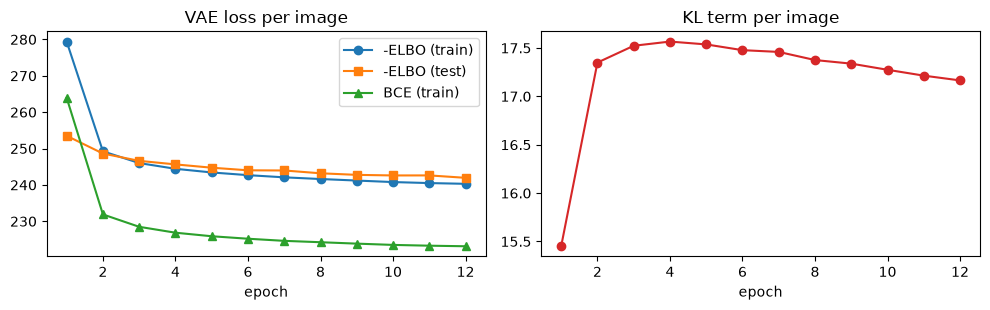

In [12]:
def vae_loss(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return bce + kl, bce, kl

opt = torch.optim.Adam(vae.parameters(), lr=2e-3)
EPOCHS_VAE = 12
vae_hist = []
t0 = time.time()
for epoch in range(1, EPOCHS_VAE + 1):
    vae.train(); s = np.zeros(3)
    for x, _ in tqdm(train_loader, desc=f"VAE epoch {epoch}", leave=False):
        x = x.to(device)
        recon, mu, logvar = vae(x)
        loss, bce, kl = vae_loss(recon, x, mu, logvar)
        opt.zero_grad(); loss.backward(); opt.step()
        s += [loss.item(), bce.item(), kl.item()]
    s /= len(train_loader)
    vae.eval(); t = np.zeros(3)
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device); r, mu, lv = vae(x); l = vae_loss(r, x, mu, lv); t += [v.item() * x.size(0) for v in l]
    t /= len(test_ds)
    vae_hist.append({"epoch": epoch, "elbo_loss": s[0], "bce": s[1], "kl": s[2], "test_elbo_loss": t[0], "test_bce": t[1], "test_kl": t[2]})
    print(f"epoch {epoch:2d} | -ELBO {s[0]:7.2f} = BCE {s[1]:7.2f} + KL {s[2]:5.2f} | test -ELBO {t[0]:7.2f}")
METRICS["vae_train_minutes"] = round((time.time() - t0) / 60, 2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ep = [h["epoch"] for h in vae_hist]
ax[0].plot(ep, [h["elbo_loss"] for h in vae_hist], "o-", label="-ELBO (train)")
ax[0].plot(ep, [h["test_elbo_loss"] for h in vae_hist], "s-", label="-ELBO (test)")
ax[0].plot(ep, [h["bce"] for h in vae_hist], "^-", label="BCE (train)"); ax[0].set_title("VAE loss per image"); ax[0].legend()
ax[1].plot(ep, [h["kl"] for h in vae_hist], "o-", c="tab:red"); ax[1].set_title("KL term per image")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(RESULTS / "vae_elbo_bce_kl.png", dpi=130); plt.show()

## 3.4 Samples, interpolations and traversals
### Figure 2: random samples from the prior z ~ N(0, I)

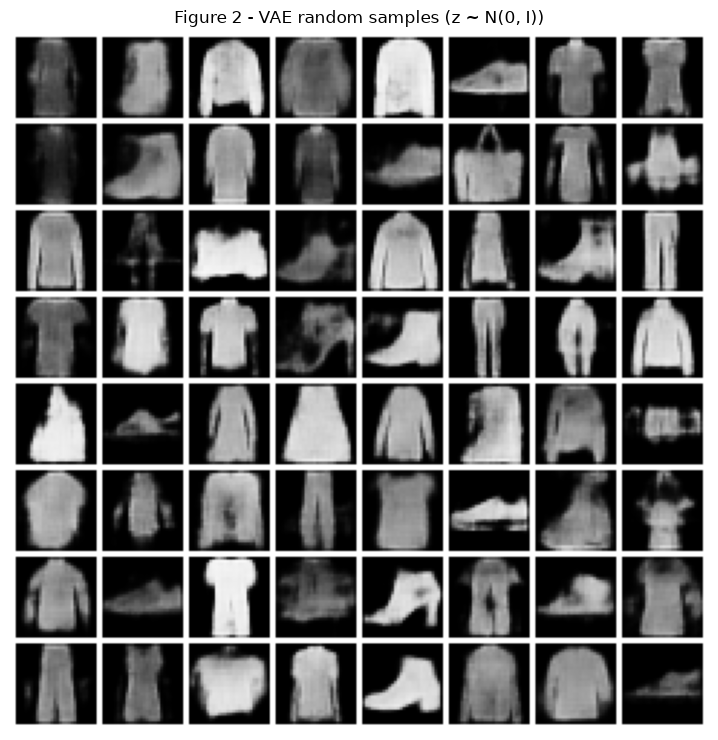

In [13]:
vae.eval(); torch.manual_seed(SEED)
with torch.no_grad():
    samples = vae.dec(torch.randn(64, LATENT_VAE, device=device))
show_grid(samples, nrow=8, title="Figure 2 - VAE random samples (z ~ N(0, I))", save="fig2_vae_random_samples.png", figsize=(7.5, 7.5))

### Figure 3: interpolations between test images (linear path between their μ codes)

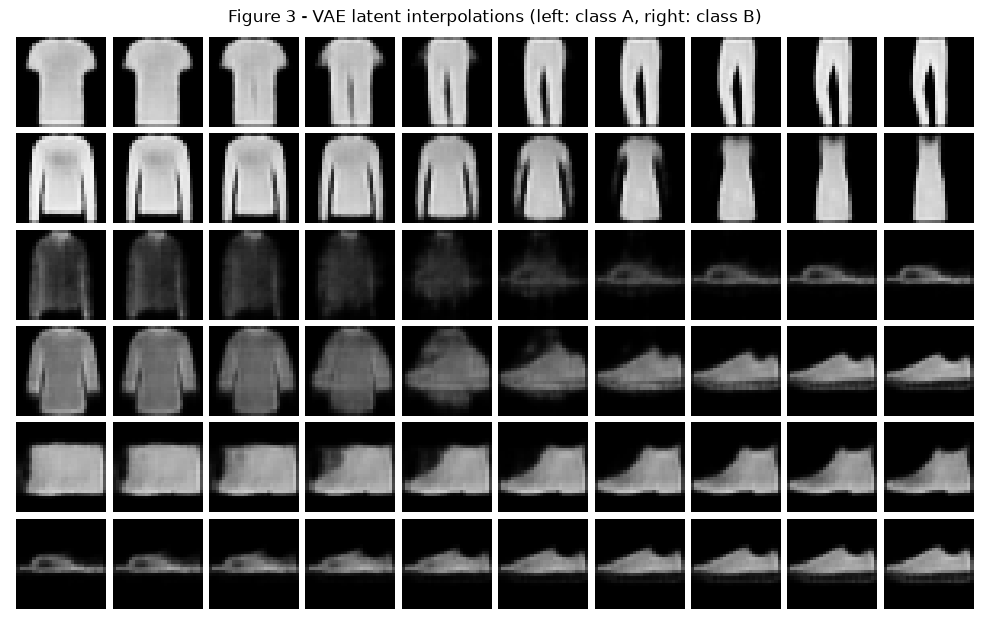

rows: ['T-shirt/top -> Trouser', 'Pullover -> Dress', 'Coat -> Sandal', 'Shirt -> Sneaker', 'Bag -> Ankle boot', 'Sandal -> Sneaker']


In [14]:
pairs = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (5, 7)]          # (class A, class B)
first_idx = {c: (test_ds.targets == c).nonzero()[0].item() for c in range(10)}
rows = []
with torch.no_grad():
    for a, b in pairs:
        xa = test_ds[first_idx[a]][0].unsqueeze(0).to(device); xb = test_ds[first_idx[b]][0].unsqueeze(0).to(device)
        ma, _ = vae.encode(xa); mb, _ = vae.encode(xb)
        ts = torch.linspace(0, 1, 10, device=device).view(-1, 1)
        rows.append(vae.dec((1 - ts) * ma + ts * mb))
show_grid(torch.cat(rows), nrow=10, title="Figure 3 - VAE latent interpolations (left: class A, right: class B)",
          save="fig3_vae_interpolations.png", figsize=(10, 6.5))
print("rows:", [f"{CLASSES[a]} -> {CLASSES[b]}" for a, b in pairs])

### Figure 4: latent traversals of the most-used dimensions

KL per latent dim: [1.45 0.79 0.76 1.13 0.37 0.47 1.27 1.15 0.5  1.83 1.79 2.63 0.71 1.66
 0.61 0.19]
most informative dims: [11, 9, 10, 13, 0, 6]


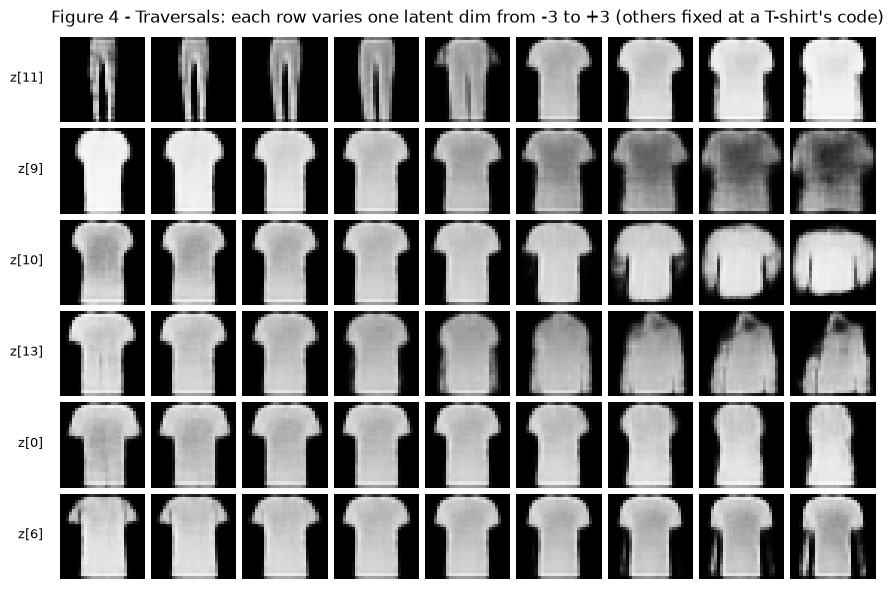

In [15]:
# which latent dimensions carry information? average KL per dimension over the test set
kl_dim = torch.zeros(LATENT_VAE); mus, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, lv = vae.encode(x.to(device))
        kl_dim += (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).sum(0).cpu(); mus.append(mu.cpu()); labels.append(y)
kl_dim /= len(test_ds); mus = torch.cat(mus); labels = torch.cat(labels)
active = kl_dim.argsort(descending=True)[:6].tolist()
METRICS["vae"] = {"final": vae_hist[-1], "kl_per_dim": [round(v, 3) for v in kl_dim.tolist()],
                  "active_dims_kl_gt_0.1": int((kl_dim > 0.1).sum()), "top_dims": active}
print("KL per latent dim:", np.round(kl_dim.numpy(), 2)); print("most informative dims:", active)

base = test_ds[first_idx[0]][0].unsqueeze(0).to(device)           # a T-shirt as the starting point
with torch.no_grad():
    mu0, _ = vae.encode(base)
    vals = torch.linspace(-3, 3, 9, device=device)
    rows = []
    for d in active:
        z = mu0.repeat(9, 1); z[:, d] = vals; rows.append(vae.dec(z))
fig, ax = plt.subplots(figsize=(9, 6.6))
show_grid(torch.cat(rows), nrow=9, ax=ax)
ax.set_title("Figure 4 - Traversals: each row varies one latent dim from -3 to +3 (others fixed at a T-shirt's code)")
for i, d in enumerate(active):
    ax.text(-4, 15 + i * 30, f"z[{d}]", ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS / "fig4_vae_traversals.png", dpi=130, bbox_inches="tight"); plt.show()

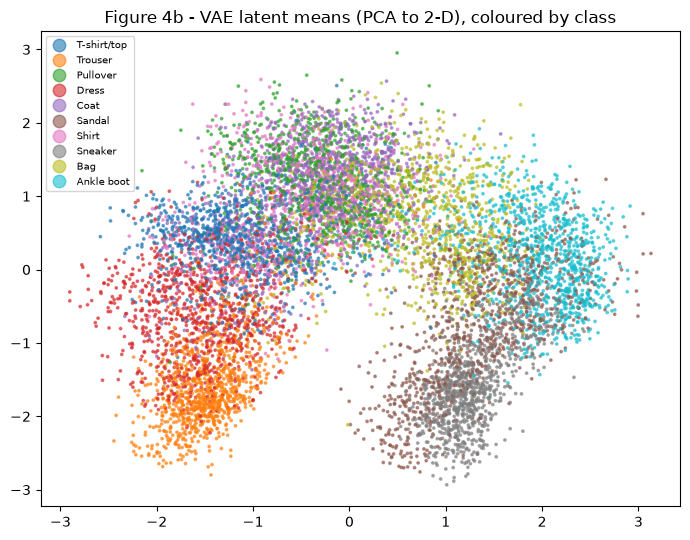

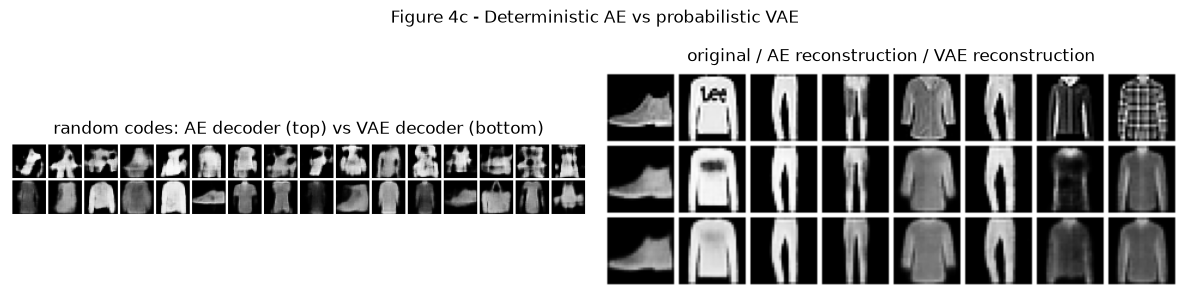

{'ae': 0.01149740256369114, 'vae_mu': 0.013587678782641888}


In [16]:
# Figure 4b: the latent space itself (2-D PCA of mu, coloured by class)
from sklearn.decomposition import PCA
p = PCA(2, random_state=SEED).fit_transform(mus.numpy())
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(p[:, 0], p[:, 1], c=labels.numpy(), cmap="tab10", s=3, alpha=.6)
plt.legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=7, markerscale=1.5, loc="best")
plt.title("Figure 4b - VAE latent means (PCA to 2-D), coloured by class")
plt.tight_layout(); plt.savefig(RESULTS / "fig4b_vae_latent_pca.png", dpi=130); plt.show()

# Figure 4c: why the probabilistic latent matters - decode the SAME random vectors with the AE and the VAE decoder
torch.manual_seed(SEED)
with torch.no_grad():
    ae_codes = []
    for x, _ in test_loader: ae_codes.append(dae.enc(x.to(device)).cpu())
    ae_codes = torch.cat(ae_codes)
    z_ae = (torch.randn(16, LATENT_AE) * ae_codes.std(0) + ae_codes.mean(0)).to(device)   # Gaussian matched to AE codes
    ae_rand = dae.dec(z_ae); vae_rand = vae.dec(torch.randn(16, LATENT_VAE, device=device))
    xr = next(iter(test_loader))[0][:8].to(device)
    ae_rec, vae_rec = dae(xr), vae.dec(vae.encode(xr)[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
show_grid(torch.cat([ae_rand, vae_rand]), nrow=16, ax=axes[0], title="random codes: AE decoder (top) vs VAE decoder (bottom)")
show_grid(torch.cat([xr, ae_rec, vae_rec]), nrow=8, ax=axes[1], title="original / AE reconstruction / VAE reconstruction")
plt.suptitle("Figure 4c - Deterministic AE vs probabilistic VAE"); plt.tight_layout()
plt.savefig(RESULTS / "fig4c_ae_vs_vae.png", dpi=130, bbox_inches="tight"); plt.show()
with torch.no_grad():
    METRICS["recon_mse_clean_input"] = {"ae": F.mse_loss(ae_rec, xr).item(), "vae_mu": F.mse_loss(vae_rec, xr).item()}
print(METRICS["recon_mse_clean_input"])

**Traversal notes**

- **z[11]** (highest KL, 2.6 nats) controls the garment type and width: at −3 the T-shirt turns into narrow trousers, and at +3 it becomes a brighter, wider top.
- **z[9]** mostly controls brightness and contrast: from a bright white shirt at −3 to a darker garment with a shaded centre at +3.
- **z[10]** adds long sleeves and widens the body, so the T-shirt turns into a pullover-like shape.
- **z[13]** introduces an asymmetric collar or front opening, so the top turns into a jacket or coat. **z[6]** gradually adds sleeve length.
- All 16 dimensions are active (KL > 0.1 nats), but the factors are entangled: one dimension changes several attributes at once (shape and brightness), as expected from a plain VAE (β = 1).

**Observations: AE vs VAE**

- **Sampling:** decoding random codes with the AE decoder gives broken blobs, because its latent space has gaps between the training codes. The VAE decoder turns every N(0, I) sample into a plausible garment or shoe (Figures 2 and 4c).
- **Reconstruction:** the deterministic AE reconstructs slightly better (MSE 0.0115 vs 0.0136 for the VAE's mean code). The KL term costs some detail, so VAE outputs are a little blurrier.
- **Latent structure:** the VAE's KL term organises the space. Classes form clusters, with tops, trousers, shoes and bags in distinct regions (Figure 4b), and interpolations change smoothly (Figure 3).
- **Interpolations:** within related shapes (T-shirt → trouser, pullover → dress) every step is a valid garment. Across distant classes (tops → sandals) the midpoints become faint blobs, showing low-density regions between clusters.
- **Trade-off:** the AE is a better compressor and denoiser; the VAE is a usable generative model with an ELBO of about 242 nats per image (BCE 224.6 + KL 17.3 on test).

# Task 4: Conditional GAN

## 4.1 Architecture
- **Generator:** noise z (100-dim) is **concatenated with a learned 50-dim label embedding**. A linear layer maps this to 128×7×7, then two transposed convolutions with BatchNorm upsample to 28×28, finished with **Tanh** (images scaled to [−1, 1]).
- **Discriminator:** the label is embedded into a **28×28 label map** and stacked with the image as a second input channel. Two stride-2 convolutions with LeakyReLU (and dropout for stability) feed a linear layer that outputs one **logit**. So the discriminator judges "is this a real image *of this class*?".

In [17]:
Z_DIM, EMB = 100, 50

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(10, EMB)
        self.fc = nn.Sequential(nn.Linear(Z_DIM + EMB, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),     # 7 -> 14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())                          # 14 -> 28
    def forward(self, z, y):
        h = torch.cat([z, self.emb(y)], dim=1)                                     # concat z with label embedding
        return self.net(self.fc(h).view(-1, 128, 7, 7))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_map = nn.Embedding(10, 28 * 28)                                 # label -> 28x28 map
        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, 2, 1), nn.LeakyReLU(0.2), nn.Dropout(0.3),          # 28 -> 14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2), nn.Dropout(0.3),  # 14 -> 7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))                                # logit
    def forward(self, x, y):
        m = self.label_map(y).view(-1, 1, 28, 28)
        return self.net(torch.cat([x, m], dim=1)).squeeze(1)

G, D = Generator().to(device), Discriminator().to(device)
print("G params:", sum(p.numel() for p in G.parameters()), "| D params:", sum(p.numel() for p in D.parameters()))

G params: 1092405 | D params: 147681


## 4.2 Training
- **Loss:** BCEWithLogits, with **one-sided label smoothing** (real target = 0.9) so the discriminator doesn't become overconfident.
- **Optimiser:** Adam (lr 2e-4, betas 0.5 and 0.999), 15 epochs.
- **Each step:** (1) update D on real images (target 0.9) and fake images (target 0); (2) update G so that D labels its fakes as real (target 1). G gets fresh random labels each step.
- **Logged per epoch:** D loss, G loss, the mean D(x) on real images, and D(G(z)) on fakes.
- **Monitoring:** after every epoch, a grid of labels 0-9 is drawn with a **fixed** z, so progress is comparable across epochs.

epoch  1 | loss D 1.035 | loss G 1.602 | D(x) 0.60 | D(G(z)) 0.30


epoch  2 | loss D 1.207 | loss G 1.139 | D(x) 0.53 | D(G(z)) 0.37


epoch  3 | loss D 1.105 | loss G 1.303 | D(x) 0.57 | D(G(z)) 0.33


epoch  4 | loss D 1.051 | loss G 1.443 | D(x) 0.59 | D(G(z)) 0.30


epoch  5 | loss D 1.027 | loss G 1.543 | D(x) 0.61 | D(G(z)) 0.29


...

epoch 11 | loss D 0.943 | loss G 1.866 | D(x) 0.66 | D(G(z)) 0.24


epoch 12 | loss D 0.932 | loss G 1.889 | D(x) 0.66 | D(G(z)) 0.24


epoch 13 | loss D 0.947 | loss G 1.878 | D(x) 0.66 | D(G(z)) 0.24


epoch 14 | loss D 0.930 | loss G 1.921 | D(x) 0.66 | D(G(z)) 0.23


epoch 15 | loss D 0.857 | loss G 2.044 | D(x) 0.69 | D(G(z)) 0.21


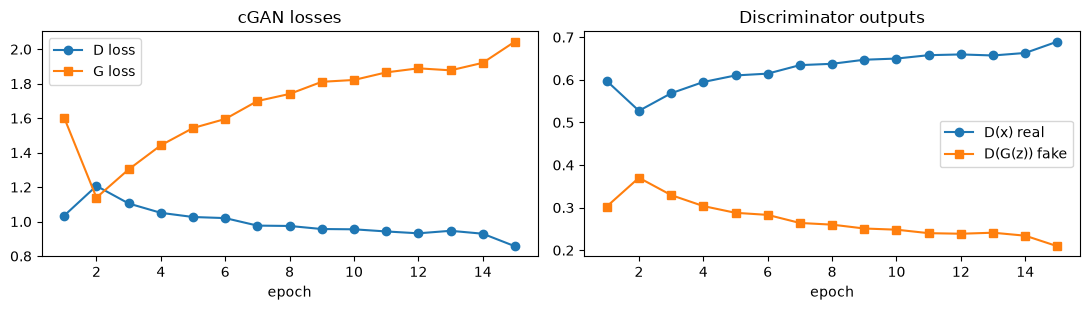

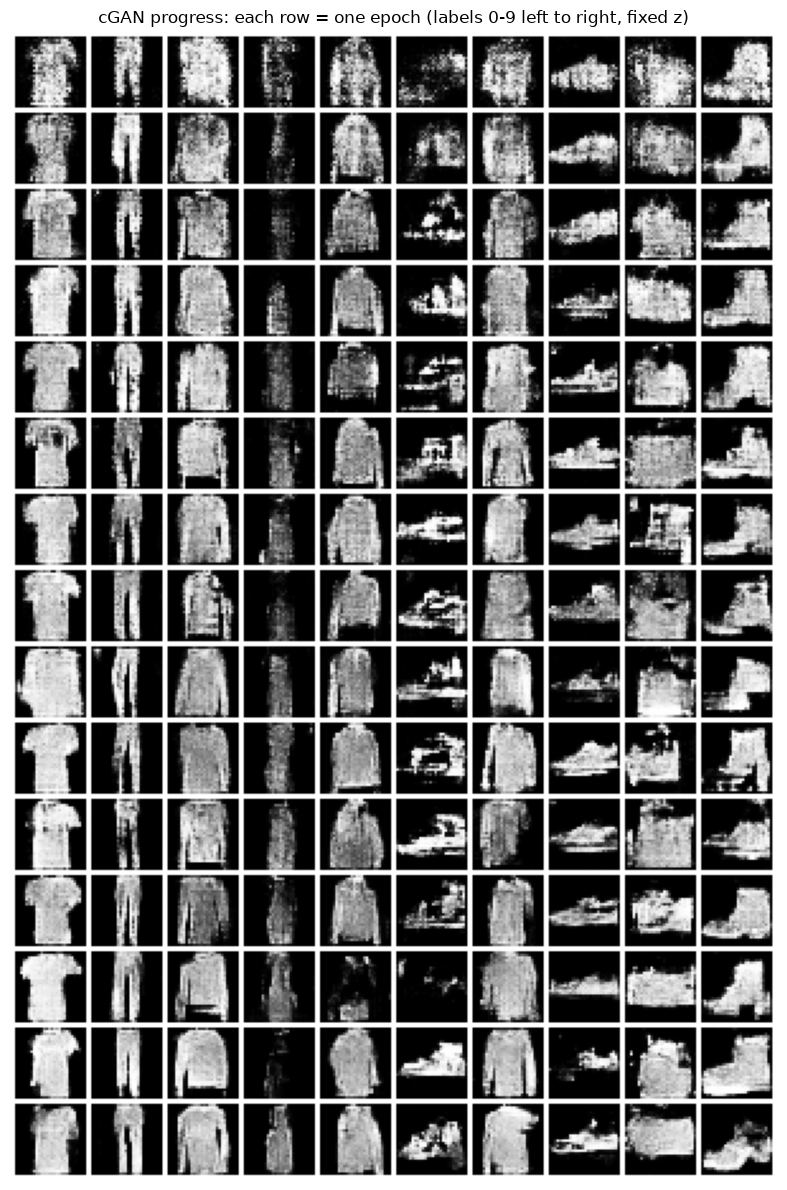

In [18]:
to_gan = lambda x: x * 2 - 1                          # [0,1] -> [-1,1] to match Tanh
crit = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
EPOCHS_GAN, REAL = 15, 0.9
torch.manual_seed(SEED)
fixed_z = torch.randn(10, Z_DIM, device=device); fixed_y = torch.arange(10, device=device)
gan_hist, epoch_grids = [], []
t0 = time.time()
for epoch in range(1, EPOCHS_GAN + 1):
    G.train(); D.train(); s = np.zeros(4)
    for x, y in tqdm(train_loader, desc=f"cGAN epoch {epoch}", leave=False):
        x, y = to_gan(x.to(device)), y.to(device); b = x.size(0)
        # --- D step: real (target 0.9) + fake (target 0)
        z = torch.randn(b, Z_DIM, device=device); fake = G(z, y)
        d_real, d_fake = D(x, y), D(fake.detach(), y)
        lossD = crit(d_real, torch.full_like(d_real, REAL)) + crit(d_fake, torch.zeros_like(d_fake))
        optD.zero_grad(); lossD.backward(); optD.step()
        # --- G step: make D call fakes real (fresh labels)
        yg = torch.randint(0, 10, (b,), device=device)
        out = D(G(torch.randn(b, Z_DIM, device=device), yg), yg)
        lossG = crit(out, torch.ones_like(out))
        optG.zero_grad(); lossG.backward(); optG.step()
        s += [lossD.item(), lossG.item(), torch.sigmoid(d_real).mean().item(), torch.sigmoid(d_fake).mean().item()]
    s /= len(train_loader)
    gan_hist.append({"epoch": epoch, "loss_D": s[0], "loss_G": s[1], "D(x)": s[2], "D(G(z))": s[3]})
    G.eval()
    with torch.no_grad():
        epoch_grids.append(G(fixed_z, fixed_y).cpu())
    print(f"epoch {epoch:2d} | loss D {s[0]:.3f} | loss G {s[1]:.3f} | D(x) {s[2]:.2f} | D(G(z)) {s[3]:.2f}")
METRICS["cgan_train_minutes"] = round((time.time() - t0) / 60, 2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2)); ep = [h["epoch"] for h in gan_hist]
ax[0].plot(ep, [h["loss_D"] for h in gan_hist], "o-", label="D loss"); ax[0].plot(ep, [h["loss_G"] for h in gan_hist], "s-", label="G loss")
ax[0].legend(); ax[0].set_title("cGAN losses")
ax[1].plot(ep, [h["D(x)"] for h in gan_hist], "o-", label="D(x) real"); ax[1].plot(ep, [h["D(G(z))"] for h in gan_hist], "s-", label="D(G(z)) fake")
ax[1].legend(); ax[1].set_title("Discriminator outputs"); [a.set_xlabel("epoch") for a in ax]
plt.tight_layout(); plt.savefig(RESULTS / "cgan_losses.png", dpi=130); plt.show()

show_grid(torch.cat(epoch_grids), nrow=10, title="cGAN progress: each row = one epoch (labels 0-9 left to right, fixed z)",
          save="cgan_epoch_progress.png", figsize=(8, 12))

## 4.3 Samples
### Figure 5: one generated sample per class (0-9)

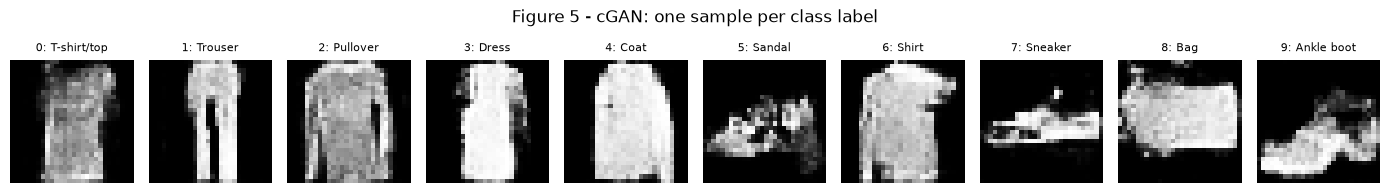

In [19]:
G.eval(); torch.manual_seed(7)
with torch.no_grad():
    per_class = G(torch.randn(10, Z_DIM, device=device), torch.arange(10, device=device))
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(((per_class[i, 0].cpu() + 1) / 2).numpy(), cmap="gray"); ax.axis("off"); ax.set_title(f"{i}: {CLASSES[i]}", fontsize=8)
plt.suptitle("Figure 5 - cGAN: one sample per class label"); plt.tight_layout()
plt.savefig(RESULTS / "fig5_cgan_per_class.png", dpi=130, bbox_inches="tight"); plt.show()

### Figure 6: diversity grid (each row = one class, 10 different z)

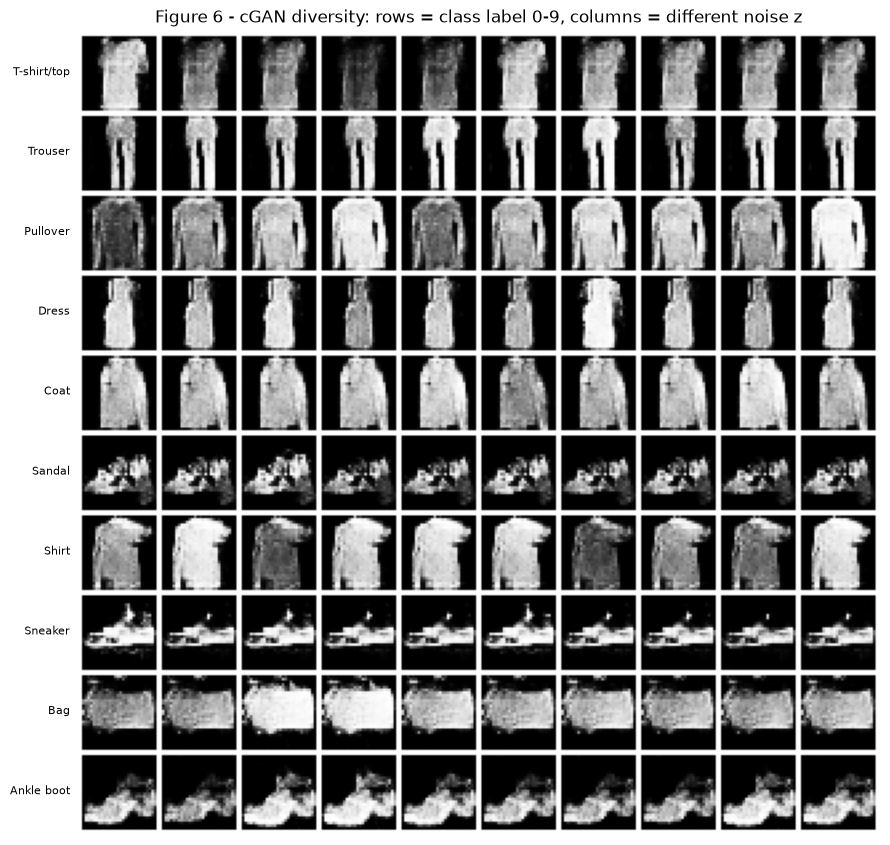

In [20]:
torch.manual_seed(SEED)
with torch.no_grad():
    ys = torch.arange(10, device=device).repeat_interleave(10)
    div = G(torch.randn(100, Z_DIM, device=device), ys)
fig, ax = plt.subplots(figsize=(9, 9.6))
show_grid(div, nrow=10, ax=ax)
for i in range(10): ax.text(-3, 15 + i * 30, CLASSES[i], ha="right", va="center", fontsize=8)
ax.set_title("Figure 6 - cGAN diversity: rows = class label 0-9, columns = different noise z")
plt.tight_layout(); plt.savefig(RESULTS / "fig6_cgan_diversity.png", dpi=130, bbox_inches="tight"); plt.show()

### Does the label really control the output?
A small CNN classifier is trained on real Fashion-MNIST, then used to label 1,000 generated images (100 per class). If conditioning works, its predictions should match the labels we asked for. **Diversity** is measured as the average pixel distance between different samples of the same class, compared with real images of that class.

In [21]:
clf = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
optC = torch.optim.Adam(clf.parameters(), 1e-3)
for epoch in range(3):
    clf.train()
    for x, y in train_loader:
        loss = F.cross_entropy(clf(x.to(device)), y.to(device)); optC.zero_grad(); loss.backward(); optC.step()
clf.eval(); correct = 0
with torch.no_grad():
    for x, y in test_loader: correct += (clf(x.to(device)).argmax(1).cpu() == y).sum().item()
clf_acc = correct / len(test_ds)

torch.manual_seed(SEED)
with torch.no_grad():
    ys = torch.arange(10, device=device).repeat_interleave(100)
    gen = (G(torch.randn(1000, Z_DIM, device=device), ys) + 1) / 2
    pred = clf(gen).argmax(1)
cond_acc = (pred == ys).float().mean().item()
per_cls = {CLASSES[c]: (pred[ys == c] == c).float().mean().item() for c in range(10)}
conf = torch.zeros(10, 10, dtype=torch.int)
for t, p_ in zip(ys.cpu(), pred.cpu()): conf[t, p_] += 1

def mean_pairwise(imgs):
    f = imgs.flatten(1); d = torch.cdist(f, f); n = len(f)
    return (d.sum() / (n * (n - 1))).item()
div_gen = {CLASSES[c]: mean_pairwise(gen[ys == c][:50].cpu()) for c in range(10)}
div_real = {CLASSES[c]: mean_pairwise(test_ds.data[test_ds.targets == c][:50].float().unsqueeze(1) / 255) for c in range(10)}
METRICS["cgan"] = {"final": gan_hist[-1], "classifier_test_acc": clf_acc, "conditional_accuracy": cond_acc,
                   "per_class_conditional_accuracy": per_cls, "diversity_generated": div_gen, "diversity_real": div_real,
                   "confused_pairs": sorted([(CLASSES[i], CLASSES[j], int(conf[i, j])) for i in range(10) for j in range(10) if i != j],
                                            key=lambda t: -t[2])[:4]}
print(f"classifier accuracy on real test images: {clf_acc:.1%}")
print(f"conditional accuracy of generated images: {cond_acc:.1%} (chance = 10%)")
for k in CLASSES: print(f"  {k:12s} cond. acc {per_cls[k]:.0%} | diversity gen {div_gen[k]:.2f} vs real {div_real[k]:.2f}")
print("most confused (asked -> predicted, count):", METRICS["cgan"]["confused_pairs"])

classifier accuracy on real test images: 89.3%
conditional accuracy of generated images: 99.8% (chance = 10%)
  T-shirt/top  cond. acc 100% | diversity gen 4.70 vs real 8.25
  Trouser      cond. acc 100% | diversity gen 1.99 vs real 6.43
  Pullover     cond. acc 100% | diversity gen 4.21 vs real 9.74
  Dress        cond. acc 100% | diversity gen 3.01 vs real 8.35
  Coat         cond. acc 100% | diversity gen 2.29 vs real 8.95
  Sandal       cond. acc 100% | diversity gen 2.31 vs real 8.42
  Shirt        cond. acc 98% | diversity gen 3.91 vs real 9.61
  Sneaker      cond. acc 100% | diversity gen 1.73 vs real 6.70
  Bag          cond. acc 100% | diversity gen 3.08 vs real 11.27
  Ankle boot   cond. acc 100% | diversity gen 3.42 vs real 8.79
most confused (asked -> predicted, count): [('Shirt', 'Pullover', 2), ('T-shirt/top', 'Trouser', 0), ('T-shirt/top', 'Pullover', 0), ('T-shirt/top', 'Dress', 0)]


**Observations: conditioning behaviour**

- **Labels control the class almost perfectly:** a separate CNN classifier (89.3% accurate on real images) recognises **99.8%** of 1,000 generated images as the requested class. Every class scores 100%, except Shirt at 98%, where 2 images look like pullovers (Figures 5 and 6).
- **Low within-class diversity (partial mode collapse):** different z values for the same label mostly change brightness, not shape. Average pairwise distance between samples is only 1.7-4.7, against 6.4-11.3 for real images of the same class. Sneakers, sandals and ankle boots are nearly identical across z.
- **Sharper but noisier than the VAE:** edges and dark backgrounds are crisp, and there is no blur. But textures are speckled, and sandal straps are rendered as noisy blobs, which is a typical GAN artefact at this model size and training length.
- **Training dynamics:** with the real target smoothed to 0.9, D(x) settles around 0.6-0.7 and D(G(z)) falls slowly from 0.30 to 0.21. Meanwhile the G loss rises from 1.6 to 2.0, so the discriminator is gradually winning. Training stayed stable for 15 epochs, but longer runs would need tweaks such as more dropout or a lower D learning rate.
- **The label also guides the discriminator:** the 28×28 label map lets D reject well-drawn images of the wrong class. That forces G to respect the label instead of drawing whichever class is easiest.
- **Progress grid:** class identity appears within the first 1-2 epochs. Later epochs mainly sharpen details such as collars, heels and bag handles.

# Task 5: StyleGAN-lite (AdaIN demo)

## 5.1 How it works
**Adaptive Instance Normalisation** re-styles the content's feature maps with the style's per-channel statistics:

AdaIN(c, s) = σ(s) · (c − μ(c)) / σ(c) + μ(s)

In StyleGAN this is how a "style" vector controls every layer. As a toy version:
1. Train a small **fully-convolutional autoencoder**, so its 64×7×7 feature maps keep the spatial layout.
2. Encode 8 **content** images and 8 **style** images.
3. Apply AdaIN to the content features with each style's channel means and standard deviations.
4. Decode the result.

Content provides *where* things are (shape). Style provides *how strongly each feature fires* (texture, thickness, brightness).

In [22]:
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU())        # 64x7x7
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())
    def forward(self, x):
        return self.dec(self.enc(x))

def adain(content_feat, style_feat, eps=1e-5):
    c_mu, c_std = content_feat.mean((2, 3), keepdim=True), content_feat.std((2, 3), keepdim=True) + eps
    s_mu, s_std = style_feat.mean((2, 3), keepdim=True), style_feat.std((2, 3), keepdim=True) + eps
    return s_std * (content_feat - c_mu) / c_std + s_mu

cae = ConvAE().to(device); optA = torch.optim.Adam(cae.parameters(), 1e-3)
for epoch in range(1, 6):
    cae.train(); tr = 0
    for x, _ in tqdm(train_loader, desc=f"ConvAE epoch {epoch}", leave=False):
        x = x.to(device); loss = F.mse_loss(cae(x), x); optA.zero_grad(); loss.backward(); optA.step(); tr += loss.item()
    print(f"ConvAE epoch {epoch} | recon MSE {tr / len(train_loader):.4f}")

ConvAE epoch 1 | recon MSE 0.0112


ConvAE epoch 2 | recon MSE 0.0020


ConvAE epoch 3 | recon MSE 0.0012


ConvAE epoch 4 | recon MSE 0.0009


ConvAE epoch 5 | recon MSE 0.0007


## 5.2 Figure 7: content | style | mixed

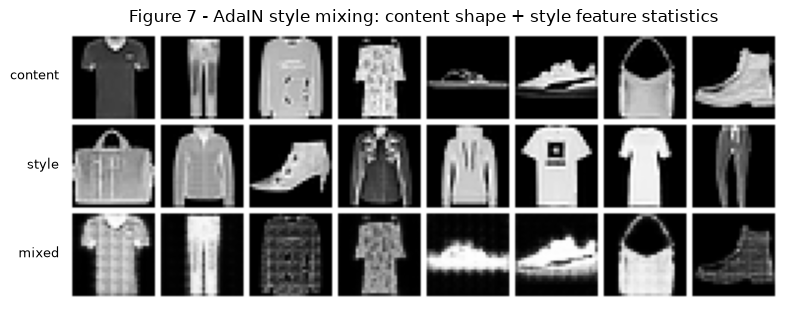

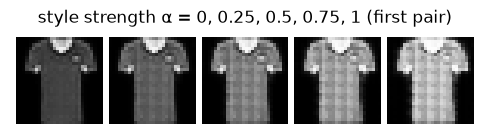

{
 "feature_mean_gap_to_style": 0.10903656482696533,
 "feature_mean_gap_to_content": 0.20184633135795593,
 "silhouette_corr_with_content": 0.6250141693560849,
 "silhouette_corr_with_style": 0.1548194507603015,
 "mean_brightness": {
  "content": 0.24761530756950378,
  "style": 0.3300507664680481,
  "mixed": 0.26937246322631836
 }
}


In [23]:
cae.eval()
content_cls = [0, 1, 2, 3, 5, 7, 8, 9]          # T-shirt, Trouser, Pullover, Dress, Sandal, Sneaker, Bag, Ankle boot
style_cls = [8, 4, 9, 6, 2, 0, 3, 1]            # deliberately different classes
content = torch.stack([test_ds[(test_ds.targets == c).nonzero()[3].item()][0] for c in content_cls]).to(device)
style = torch.stack([test_ds[(test_ds.targets == c).nonzero()[10].item()][0] for c in style_cls]).to(device)
with torch.no_grad():
    fc, fs = cae.enc(content), cae.enc(style)
    mixed = cae.dec(adain(fc, fs))
    alphas = [0, 0.25, 0.5, 0.75, 1.0]
    blend = torch.cat([cae.dec((1 - a) * fc[:1] + a * adain(fc[:1], fs[:1])) for a in alphas])
fig, ax = plt.subplots(figsize=(8, 3.6))
show_grid(torch.cat([content, style, mixed]), nrow=8, ax=ax)
for i, t in enumerate(["content", "style", "mixed"]): ax.text(-3, 15 + i * 30, t, ha="right", va="center", fontsize=9)
ax.set_title("Figure 7 - AdaIN style mixing: content shape + style feature statistics")
plt.tight_layout(); plt.savefig(RESULTS / "fig7_adain_content_style_mixed.png", dpi=130, bbox_inches="tight"); plt.show()
show_grid(blend, nrow=5, title="style strength α = 0, 0.25, 0.5, 0.75, 1 (first pair)", save="fig7b_adain_alpha.png", figsize=(5, 1.4))

with torch.no_grad():
    stat = lambda f: (f.mean((2, 3)), f.std((2, 3)))
    fm = cae.enc(mixed)
    d_style = (stat(fm)[0] - stat(fs)[0]).abs().mean().item(); d_content = (stat(fm)[0] - stat(fc)[0]).abs().mean().item()
    shape_corr = np.mean([np.corrcoef(mixed[i].cpu().flatten() > .3, content[i].cpu().flatten() > .3)[0, 1] for i in range(8)])
    style_corr = np.mean([np.corrcoef(mixed[i].cpu().flatten() > .3, style[i].cpu().flatten() > .3)[0, 1] for i in range(8)])
METRICS["adain"] = {"feature_mean_gap_to_style": d_style, "feature_mean_gap_to_content": d_content,
                    "silhouette_corr_with_content": float(shape_corr), "silhouette_corr_with_style": float(style_corr),
                    "mean_brightness": {"content": content.mean().item(), "style": style.mean().item(), "mixed": mixed.mean().item()}}
print(json.dumps(METRICS["adain"], indent=1))

**Observations (AdaIN)**

- **Shape comes from the content image:** the mixed image's silhouette correlates with the content (r = 0.63) far more than with the style (r = 0.15). The trousers stay trousers and the bag stays a bag.
- **Appearance comes from the style image:** AdaIN copies the style's per-channel feature statistics, and the mixed features end up much closer to the style's (mean gap 0.11) than to the content's (0.20). This shows as transferred texture (grid or plaid patterns, stripes) and brightness. Mean brightness moves from 0.25 (content) towards the style's 0.33. The α slider blends this gradually.
- **Limitation:** when the style comes from a bulky, bright garment and the content is thin (the sandal), the borrowed statistics over-activate the features and the shape blows out. This is the same content/style balance that StyleGAN controls per layer.

# Analysis and short report

A separate 1-2 page PDF (Week 19_Graded Mini Project_Jain_Analysis.pdf) contains the same analysis.

### AE vs VAE (deterministic vs probabilistic)

- The AE maps each image to a single point and only learns to reconstruct, which gives it slightly better reconstructions (MSE 0.0115 vs 0.0136) and makes it an effective denoiser (+7.7 dB PSNR).
- The VAE maps each image to a distribution and adds a KL penalty towards N(0, I). This fills the space between codes, so random samples, interpolations and traversals decode to plausible clothes. Random AE codes decode to unusable blobs.
- The price is a little blur, and factors that are entangled rather than cleanly separated.

### VAE vs cGAN (likelihood vs adversarial)

- The VAE maximises a likelihood bound (BCE + KL). That covers all the data, giving diverse samples and a smooth, meaningful latent space, but per-pixel losses average details and produce blur.
- The cGAN has no reconstruction loss. A discriminator judges realism, which gives sharper edges and darker backgrounds, but it is prone to mode collapse: within-class diversity is only about 25-55% of the real data's, and there is speckle noise.
- The VAE has an encoder and a training objective you can read and log. The GAN's losses can't be read as quality; it needs visual checks plus external metrics such as the classifier accuracy and diversity scores used here.

### Why labels improve control in the cGAN

- The label is given to both networks: an embedding concatenated with z in G, and a label map in D. D therefore learns "real image of this class", and G is penalised for drawing the wrong class.
- As a result, generation is steered exactly: 99.8% of samples are recognised as the requested class. In the unconditional VAE, the class can only be found by searching the latent space.
- The label splits one hard 10-mode problem into 10 easier single-class problems. This speeds up learning (class identity appears within 1-2 epochs), but it does not prevent collapse within a class.

### Takeaways: what each model captures well or poorly

- **DAE:** good at global shape, clean backgrounds and noise removal. Poor at textures, logos and thin structures, and it cannot sample.
- **VAE:** good at a smooth, sample-able latent space, interpolation and coverage of all classes. Weaker at sharpness, and its factors are entangled.
- **cGAN:** good at crisp edges and exact class control. Weaker at within-class variety and fine textures (speckle), and it needs careful monitoring.
- **AdaIN:** cleanly separates content (spatial layout) from style (channel statistics), the core idea behind StyleGAN's style control. Extreme content/style mismatches distort the shape.

### Practical notes

- **Learning rates:** Adam at 1e-3 (DAE) and 2e-3 (VAE) converged within a few epochs. The VAE loss flattens after about 6 epochs. The cGAN needs the slower 2e-4 with β1 = 0.5 to keep D and G balanced.
- **Noise:** σ = 0.3 with clamping is strong enough to hide stripes. A lower σ (0.1-0.2) would preserve more texture, and a higher one makes the DAE fall back to class-average shapes.
- **Batch size:** 128 worked for all models. BatchNorm in G and D needs batches this large, and much smaller batches make GAN training noisier.
- **Stability:** one-sided label smoothing (0.9), dropout in D and a fixed-z progress grid made the GAN trainable and easy to monitor. Signs of D gradually winning call for early stopping, or for more data augmentation / a lower D learning rate.
- **Compute:** on an Apple M1 GPU (mps) the full notebook took about 23 minutes, including 18 minutes for the cGAN. On a Colab T4 it takes about 10 minutes.

In [24]:
METRICS["dae_history"], METRICS["vae_history"], METRICS["cgan_history"] = dae_hist, vae_hist, gan_hist
json.dump(METRICS, open(RESULTS / "metrics.json", "w"), indent=2, default=float)
print("saved results/:", sorted(p.name for p in RESULTS.glob("*")))

saved results/: ['00_dataset_batch.png', 'cgan_epoch_progress.png', 'cgan_losses.png', 'dae_loss.png', 'fig1_dae_clean_noisy_denoised.png', 'fig1b_dae_failure_cases.png', 'fig2_vae_random_samples.png', 'fig3_vae_interpolations.png', 'fig4_vae_traversals.png', 'fig4b_vae_latent_pca.png', 'fig4c_ae_vs_vae.png', 'fig5_cgan_per_class.png', 'fig6_cgan_diversity.png', 'fig7_adain_content_style_mixed.png', 'fig7b_adain_alpha.png', 'metrics.json', 'vae_elbo_bce_kl.png']
